In [1]:
import json

with open(file="C:/Users/bandarua/crda_gp/data/steels_yield.json") as file:
    data = json.load(file)

data.keys()

dict_keys(['index', 'columns', 'data'])

In [2]:
import numpy as np
data_array = np.array(data['data'])

In [3]:
# Composition and yield dictionary
my_data = {}
for i in range(len(data['columns'])):
    my_data[data['columns'][i]] = []
    for j in range(len(data['data'])):
        my_data[data['columns'][i]].append(data['data'][j][i])

In [4]:
import re
my_data['split_composition'] = []
for composition in my_data['composition']:
    matches = re.findall(r'([A-Z][a-z]?)(\d*\.?\d+)', composition)
    my_data['split_composition'].append({element: float(value) for element, value in matches})
# my_data['split_composition']

In [5]:
# Get the keys
key_count = []
for key in my_data['split_composition']:
    # print(f"Key: {key.keys()}")
    # print(f"Key Length: {len(key.keys())}")
    key_count.append(key.keys())
keys = list(max(key_count))

In [6]:
composition_dict = {}

for key in keys:
    composition_dict[key] = []
    for comp in my_data['split_composition']:
        if key in list(comp.keys()):
            composition_dict[key].append(comp[key])
        else:
            composition_dict[key].append(0)

In [7]:
import pandas as pd
df = pd.DataFrame(data=composition_dict)
df

,Fe,C,Mn,Si,Cr,Ni,Mo,V,Nb,Co,W,Al,Ti
0,0.620,0.000953,0.000521,0.001020,0.000110,0.192000,0.01760,0.000112,0.000062,0.146000,0.00000,0.003180,0.01850
1,0.623,0.008540,0.000104,0.000203,0.147000,0.000097,0.01790,0.005150,0.000061,0.188000,0.00729,0.000845,0.00000
2,0.625,0.000000,0.000102,0.000200,0.093600,0.129000,0.00480,0.000110,0.000060,0.132000,0.00000,0.008120,0.00669
3,0.634,0.000478,0.000523,0.001020,0.000111,0.173000,0.02370,0.000113,0.000062,0.146000,0.00000,0.002770,0.01760
4,0.636,0.000474,0.000518,0.001010,0.000109,0.188000,0.00860,0.000112,0.000061,0.144000,0.00000,0.002740,0.01840
...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,0.823,0.017600,0.001830,0.000198,0.077900,0.000095,0.02190,0.010500,0.000060,0.046300,0.00000,0.000620,0.00000
308,0.823,0.000000,0.000618,0.001010,0.056100,0.098400,0.01890,0.000111,0.000061,0.000096,0.00000,0.000629,0.00106
309,0.825,0.017400,0.001750,0.000201,0.056500,0.000096,0.03440,0.011600,0.005540,0.046800,0.00000,0.000628,0.00000
310,0.858,0.019100,0.001940,0.000199,0.075300,0.000095,0.03410,0.010100,0.000060,0.000190,0.00000,0.000623,0.00000


In [8]:
df_targets = pd.DataFrame(my_data['yield strength'], columns=["yield_strength"])
df_targets

,yield_strength
0,2411.5
1,1123.1
2,1736.3
3,2487.3
4,2249.6
...,...
307,1722.5
308,1019.0
309,1860.3
310,1812.1


In [9]:
df_final = pd.concat([df, df_targets], axis=1)
df_final

,Fe,C,Mn,Si,Cr,Ni,Mo,V,Nb,Co,W,Al,Ti,yield_strength
0,0.620,0.000953,0.000521,0.001020,0.000110,0.192000,0.01760,0.000112,0.000062,0.146000,0.00000,0.003180,0.01850,2411.5
1,0.623,0.008540,0.000104,0.000203,0.147000,0.000097,0.01790,0.005150,0.000061,0.188000,0.00729,0.000845,0.00000,1123.1
2,0.625,0.000000,0.000102,0.000200,0.093600,0.129000,0.00480,0.000110,0.000060,0.132000,0.00000,0.008120,0.00669,1736.3
3,0.634,0.000478,0.000523,0.001020,0.000111,0.173000,0.02370,0.000113,0.000062,0.146000,0.00000,0.002770,0.01760,2487.3
4,0.636,0.000474,0.000518,0.001010,0.000109,0.188000,0.00860,0.000112,0.000061,0.144000,0.00000,0.002740,0.01840,2249.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,0.823,0.017600,0.001830,0.000198,0.077900,0.000095,0.02190,0.010500,0.000060,0.046300,0.00000,0.000620,0.00000,1722.5
308,0.823,0.000000,0.000618,0.001010,0.056100,0.098400,0.01890,0.000111,0.000061,0.000096,0.00000,0.000629,0.00106,1019.0
309,0.825,0.017400,0.001750,0.000201,0.056500,0.000096,0.03440,0.011600,0.005540,0.046800,0.00000,0.000628,0.00000,1860.3
310,0.858,0.019100,0.001940,0.000199,0.075300,0.000095,0.03410,0.010100,0.000060,0.000190,0.00000,0.000623,0.00000,1812.1


In [10]:
import numpy as np
import time
import torch
import warnings

from botorch.acquisition import LogExpectedImprovement
from botorch.exceptions import BadInitialCandidatesWarning
from botorch.exceptions import InputDataWarning
from botorch.fit import fit_gpytorch_mll
from crda_gp.bo import initialize_model_dense
from crda_gp.bo import optimize_acqf_and_get_observation
from sklearn.model_selection import train_test_split

In [11]:
X = np.array(df_final.drop(columns="yield_strength"))
y = np.array(df_final["yield_strength"])

In [12]:
from botorch.exceptions.errors import ModelFittingError
from botorch.optim.fit import fit_gpytorch_mll_scipy
from botorch.exceptions.warnings import OptimizationWarning

N_TRIALS = 20 
holdout_set_size = 0.90
N_ITERS = 20
verbose = False

warnings.filterwarnings('ignore', category=BadInitialCandidatesWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings("ignore", category=InputDataWarning)
warnings.filterwarnings('ignore', category=OptimizationWarning)
# warnings.filterswarnings

best_observed_all_ei = []

for trial in range(1, N_TRIALS + 1):

    print(f"\nTrial {trial:>2} of {N_TRIALS}", end="")
    best_observed_ei = []

    # Generate initial training data and initialize model
    train_x_ei, heldout_x_ei, train_y_ei, heldout_y_ei = train_test_split(X, y, test_size=holdout_set_size, random_state=trial)
    best_observed_value_ei = torch.tensor(np.max(train_y_ei))

    # Convert numpy arrays to PyTorch tensors and flatten the label vectors
    train_x_ei = torch.tensor(train_x_ei.astype(np.float64))
    heldout_x_ei = torch.tensor(heldout_x_ei.astype(np.float64))
    train_y_ei = torch.tensor(train_y_ei.astype(np.float64)).unsqueeze(-1)
    heldout_y_ei = torch.tensor(heldout_y_ei.astype(np.float64)).unsqueeze(-1)

    # print(f"train_x_ei: {train_x_ei.shape}")
    # print(f"train_y_ei: {train_y_ei.shape}")

    mll_ei, model_ei = initialize_model_dense(train_x_ei, train_y_ei)
    # print(type(model_ei))
    # print(type(mll_ei))
    best_observed_ei.append(best_observed_value_ei)

    for iteration in range(1, N_ITERS + 1):

        t0 = time.time()

        # print("train_x:", train_x_ei.shape)
        # print("train_y:", train_y_ei.shape)

        # print("dtype:", train_x_ei.dtype, train_y_ei.dtype)

        # print("NaNs X:", torch.isnan(train_x_ei).any().item())
        # print("NaNs Y:", torch.isnan(train_y_ei).any().item())

        # print("Infs X:", torch.isinf(train_x_ei).any().item())
        # print("Infs Y:", torch.isinf(train_y_ei).any().item())

        # print("train_y std:", train_y_ei.std().item())

        # print(model_ei.covar_module.base_kernel.lengthscale)
        # print(model_ei.covar_module.outputscale)
        # print(model_ei.likelihood.noise)

        # fit the model
        # try:
        #     fit_gpytorch_mll(mll=mll_ei, max_attempts=1)
        # except Exception as e:
        #     import traceback
        #     traceback.print_exc()
        #     raise
        fit_gpytorch_mll(mll_ei)
        # print(f"Result: {result}")
        # Use analytic acquisition function for batch size of 1.
        LogEI = LogExpectedImprovement(model=model_ei, best_f=(train_y_ei.to(train_y_ei)).max())

        new_x_ei, new_obj_ei, heldout_x_ei, heldout_y_ei = optimize_acqf_and_get_observation(LogEI, heldout_inputs=heldout_x_ei, heldout_outputs=heldout_y_ei)

        # update the training points 
        train_x_ei = torch.cat([train_x_ei, new_x_ei])
        train_y_ei = torch.cat([train_y_ei, new_obj_ei])

        best_value_ei = torch.max(new_obj_ei.squeeze(), best_observed_ei[-1])
        best_observed_ei.append(best_value_ei)

        # Reinitialize the model
        mll_ei, model_ei = initialize_model_dense(train_x_ei, train_y_ei)

        t1 = time.time()

        if verbose:
            print(f"\nBatch {iteration:>2} | best_value (EI): {best_value_ei} | time: {t1 - t0:4.2f}.", end="")
        else:
            print(".", end="")
    
    best_observed_all_ei.append(torch.hstack(best_observed_ei))


Trial  1 of 20....................
Trial  2 of 20....................
Trial  3 of 20....................
Trial  4 of 20....................
Trial  5 of 20....................
Trial  6 of 20....................
Trial  7 of 20....................
Trial  8 of 20....................
Trial  9 of 20....................
Trial 10 of 20....................
Trial 11 of 20....................
Trial 12 of 20....................
Trial 13 of 20....................
Trial 14 of 20....................
Trial 15 of 20....................
Trial 16 of 20....................
Trial 17 of 20....................
Trial 18 of 20....................
Trial 19 of 20....................
Trial 20 of 20....................

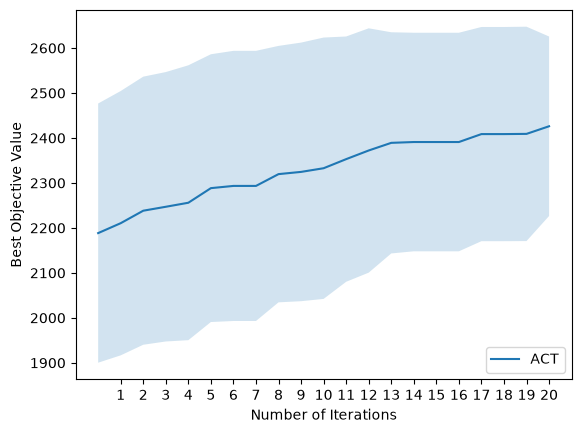

In [13]:
from crda_gp.bo import plot_confidence
plot_confidence(best_observed=best_observed_all_ei)

In [14]:
import gpytorch
from crda_gp.models import ARDExactGPModel_Dense
from crda_gp.utils import set_seed

set_seed()

X_tensor, y_tensor = torch.tensor(X, dtype=torch.double), torch.tensor(y).squeeze()
likelihood_aug = gpytorch.likelihoods.GaussianLikelihood()
model_aug = ARDExactGPModel_Dense(X_tensor, y_tensor, likelihood_aug)

In [15]:
from crda_gp.utils import train_step
train_step(X_train=X_tensor,
           y_train=y_tensor,
           model=model_aug,
           likelihood=likelihood_aug)

Iter: 10/100 | Loss: 32198.458 | Noise: 1.282
Iter: 20/100 | Loss: 20152.331 | Noise: 1.896
Iter: 30/100 | Loss: 13531.751 | Noise: 2.382
Iter: 40/100 | Loss: 10650.183 | Noise: 2.714
Iter: 50/100 | Loss: 9104.450 | Noise: 2.935
Iter: 60/100 | Loss: 8180.219 | Noise: 3.098
Iter: 70/100 | Loss: 7551.862 | Noise: 3.231
Iter: 80/100 | Loss: 7062.030 | Noise: 3.351
Iter: 90/100 | Loss: 6677.451 | Noise: 3.460
Iter: 100/100 | Loss: 6369.319 | Noise: 3.564


In [16]:
import pandas as pd
import gpytorch

set_seed()

with torch.no_grad(), gpytorch.settings.fast_pred_var():
    pred_dist = likelihood_aug(model_aug(X_tensor))
    y_new_aug = pred_dist.mean

residual = y_tensor - y_new_aug
corr = abs(pd.DataFrame(X).corrwith(pd.Series(residual.detach().numpy())))

preturb_idx= corr[abs(corr) < corr.mean().item()].sort_values(ascending=False).index.values
preturb_idx

array([ 2,  1,  0,  3,  6, 11,  8, 10])

In [17]:
from crda_gp.crda import CRDA_function
set_seed(42)
X_CRDA_tensor, y_CRDA_tensor, _, _ = CRDA_function(X_tensor, y_tensor, model=model_aug, likelihood=likelihood_aug, perturb_idx=preturb_idx, p=0.1)

Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80


c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
Iter: 109
Iter: 110
Iter: 111
Iter: 112
Iter: 113
Iter: 114
Iter: 115
Iter: 116
Iter: 117
Iter: 118
Iter: 119
Iter: 120
Iter: 121
Iter: 122
Iter: 123
Iter: 124
Iter: 125
Iter: 126
Iter: 127
Iter: 128
Iter: 129
Iter: 130
Iter: 131
Iter: 132
Iter: 133
Iter: 134
Iter: 135
Iter: 136
Iter: 137
Iter: 138
Iter: 139
Iter: 140
Iter: 141
Iter: 142
Iter: 143
Iter: 144
Iter: 145
Iter: 146
Iter: 147
Iter: 148
Iter: 149
Iter: 150
Iter: 151
Iter: 152
Iter: 153
Iter: 154
Iter: 155
Iter: 156
Iter: 157
Iter: 158
Iter: 159
Iter: 160
Iter: 161
Iter: 162
Iter: 163
Iter: 164
Iter: 165
Iter: 166
Iter: 167
Iter: 168
Iter: 169
Iter: 170
Iter: 171
Iter: 172
Iter: 173
Iter: 174
Iter: 175
Iter: 176
Iter: 177
Iter: 178
Iter: 179
Iter: 180
Iter: 181
Iter: 182

In [18]:
# Running the BO on the data
# Bayesian Optimization stuff
from botorch.exceptions.warnings import OptimizationWarning
N_TRIALS = 20 
holdout_set_size = 0.90
N_ITERS = 20
verbose = False

warnings.filterwarnings('ignore', category=BadInitialCandidatesWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=OptimizationWarning)

best_observed_all_ei, best_random_all = [], []

for trial in range(1, N_TRIALS + 1):

    print(f"\nTrial {trial:>2} of {N_TRIALS}", end="")
    best_observed_ei = []

    # Generate initial training data and initialize model
    train_x_ei, heldout_x_ei, train_y_ei, heldout_y_ei = train_test_split(X_CRDA_tensor, y_CRDA_tensor, test_size=holdout_set_size, random_state=trial)
    best_observed_value_ei = torch.max(train_y_ei)

    # Convert numpy arrays to PyTorch tensors and flatten the label vectors
    train_x_ei = train_x_ei.double()
    heldout_x_ei = heldout_x_ei.double()
    train_y_ei = train_y_ei.double()
    heldout_y_ei = heldout_y_ei.double()

    mll_ei, model_ei = initialize_model_dense(train_x_ei, train_y_ei.unsqueeze(-1))
    # print(type(model_ei))
    # print(type(mll_ei))
    best_observed_ei.append(best_observed_value_ei)

    for iteration in range(1, N_ITERS + 1):

        t0 = time.time()

        # fit the model

        fit_gpytorch_mll(mll=mll_ei)

        # Use analytic acquisition function for batch size of 1.
        LogEI = LogExpectedImprovement(model=model_ei, best_f=(train_y_ei.to(train_y_ei)).max())

        new_x_ei, new_obj_ei, heldout_x_ei, heldout_y_ei = optimize_acqf_and_get_observation(LogEI, heldout_inputs=heldout_x_ei, heldout_outputs=heldout_y_ei)

        # update the training points 
        train_x_ei = torch.cat([train_x_ei, new_x_ei])
        train_y_ei = torch.cat([train_y_ei, new_obj_ei])

        best_value_ei = torch.max(new_obj_ei, best_observed_ei[-1])
        best_observed_ei.append(best_value_ei.squeeze())

        # Reinitialize the model
        mll_ei, model_ei = initialize_model_dense(train_x_ei, train_y_ei.unsqueeze(-1),model_ei.state_dict())

        t1 = time.time()

        if verbose:
            print(f"\nBatch {iteration:>2} | best_value (EI): {best_value_ei} | time: {t1 - t0:4.2f}.", end="")
        else:
            print(".", end="")
    
    best_observed_all_ei.append(torch.hstack(best_observed_ei))


Trial  1 of 20....................
Trial  2 of 20....................
Trial  3 of 20....................
Trial  4 of 20....................
Trial  5 of 20....................
Trial  6 of 20....................
Trial  7 of 20....................
Trial  8 of 20....................
Trial  9 of 20....................
Trial 10 of 20....................
Trial 11 of 20....................
Trial 12 of 20....................
Trial 13 of 20....................
Trial 14 of 20....................
Trial 15 of 20....................
Trial 16 of 20....................
Trial 17 of 20....................
Trial 18 of 20....................
Trial 19 of 20....................
Trial 20 of 20....................

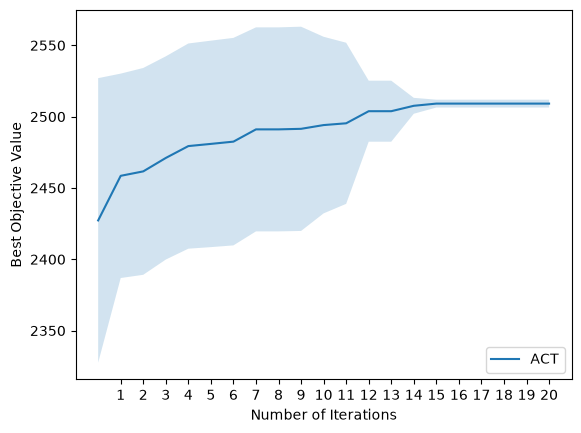

In [19]:
plot_confidence(best_observed=best_observed_all_ei)